In [1]:

import os
import platform
import pandas as pd
import time
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

os.environ["KERAS_BACKEND"] = "tensorflow"

if platform.system() == "Darwin" and platform.machine() == "arm64":
    tf.config.set_visible_devices([], "GPU")

keras.utils.set_random_seed(0)
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

class_names = [
    "lentokone",
    "auto",
    "lintu",
    "kissa",
    "peura",
    "koira",
    "sammakko",
    "hevonen",
    "laiva",
    "kuorma-auto"
]

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.perf_counter() - self.start_time
        self.epoch_times.append(elapsed)

stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                     restore_best_weights=True)

In [17]:
model_baseline = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

In [18]:
model_baseline.compile(
    optimizer="adam", 
    loss="sparse_categorical_crossentropy", 
    metrics=["accuracy"]
)

timer_baseline = EpochTimer()

history_baseline = model_baseline.fit(
    x_train, y_train, 
    epochs=20, 
    validation_split=0.1, 
    callbacks=[stop, timer_baseline], 
    verbose=2
)

history_baseline.history["epoch_time_seconds"] = timer_baseline.epoch_times

Epoch 1/20
1407/1407 - 37s - 26ms/step - accuracy: 0.4593 - loss: 1.5058 - val_accuracy: 0.5978 - val_loss: 1.1538
Epoch 2/20
1407/1407 - 33s - 23ms/step - accuracy: 0.6134 - loss: 1.1036 - val_accuracy: 0.6552 - val_loss: 0.9958
Epoch 3/20
1407/1407 - 33s - 23ms/step - accuracy: 0.6687 - loss: 0.9557 - val_accuracy: 0.6914 - val_loss: 0.9127
Epoch 4/20
1407/1407 - 32s - 23ms/step - accuracy: 0.6995 - loss: 0.8690 - val_accuracy: 0.7056 - val_loss: 0.8708
Epoch 5/20
1407/1407 - 33s - 23ms/step - accuracy: 0.7220 - loss: 0.8053 - val_accuracy: 0.7088 - val_loss: 0.8662
Epoch 6/20
1407/1407 - 32s - 23ms/step - accuracy: 0.7398 - loss: 0.7566 - val_accuracy: 0.7112 - val_loss: 0.8584
Epoch 7/20
1407/1407 - 33s - 23ms/step - accuracy: 0.7560 - loss: 0.7164 - val_accuracy: 0.7262 - val_loss: 0.8216
Epoch 8/20
1407/1407 - 33s - 23ms/step - accuracy: 0.7679 - loss: 0.6780 - val_accuracy: 0.7310 - val_loss: 0.8159
Epoch 9/20
1407/1407 - 33s - 24ms/step - accuracy: 0.7806 - loss: 0.6448 - val_a

Testin menetys (loss): 0.8838
Testin tarkkuus (accuracy): 70.98%


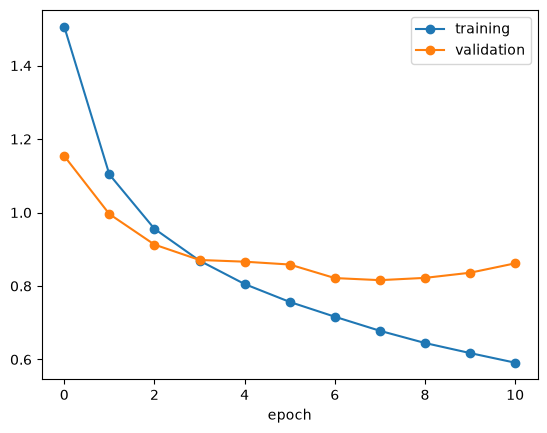

C:\Users\sakar\AppData\Local\Temp\ipykernel_37524\1630053260.py:13: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  df_times_baseline.loc[len(df_times_baseline)] = ["Keski suoritusaika", sum(timer_baseline.epoch_times) / len(timer_baseline.epoch_times)]


Epoch,Aika (s)
1,36.63
2,32.73
3,32.72
4,32.09
5,33.01
6,32.16
7,32.74
8,32.69
9,33.25
10,32.90


In [19]:
test_loss_baseline, test_accuracy_baseline = model_baseline.evaluate(x_test, y_test, verbose=0)

print(f"Testin menetys (loss): {test_loss_baseline:.4f}")
print(f"Testin tarkkuus (accuracy): {test_accuracy_baseline:.2%}")

plt.plot(history_baseline.history["loss"], marker="o", label="training")
plt.plot(history_baseline.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

df_times_baseline = pd.DataFrame({"Epoch": range(1, len(timer_baseline.epoch_times) + 1), "Aika (s)": timer_baseline.epoch_times})
df_times_baseline.loc[len(df_times_baseline)] = ["Keski suoritusaika", sum(timer_baseline.epoch_times) / len(timer_baseline.epoch_times)]
df_times_baseline.loc[len(df_times_baseline)] = ["Kokonaissuoritusaika", sum(timer_baseline.epoch_times)]

display(df_times_baseline.style.hide(axis="index").format({"Aika (s)": "{:.2f}"}))

## 5.1 Dropout
Lisätään verkkoon Dropout-kerros (0.3), joka sammuttaa satunnaisesti 30% neuroneista koulutuksen aikana. Tämän pitäisi estää verkkoa nojaamasta liikaa yksittäisiin neuroneihin ja vähentää ylisovittumista.

In [15]:
model_dropout = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model_dropout.compile(
    optimizer="adam", 
    loss="sparse_categorical_crossentropy", 
    metrics=["accuracy"]
)

timer_dropout = EpochTimer()

history_dropout = model_dropout.fit(
    x_train, y_train, 
    epochs=20, 
    validation_split=0.1, 
    callbacks=[stop, timer_dropout], 
    verbose=2
)

history_dropout.history["epoch_time_seconds"] = timer_dropout.epoch_times

Epoch 1/20
1407/1407 - 34s - 24ms/step - accuracy: 0.4335 - loss: 1.5653 - val_accuracy: 0.5642 - val_loss: 1.2298
Epoch 2/20
1407/1407 - 33s - 24ms/step - accuracy: 0.5728 - loss: 1.2079 - val_accuracy: 0.6390 - val_loss: 1.0500
Epoch 3/20
1407/1407 - 34s - 24ms/step - accuracy: 0.6260 - loss: 1.0686 - val_accuracy: 0.6766 - val_loss: 0.9419
Epoch 4/20
1407/1407 - 33s - 24ms/step - accuracy: 0.6562 - loss: 0.9859 - val_accuracy: 0.6876 - val_loss: 0.9066
Epoch 5/20
1407/1407 - 33s - 23ms/step - accuracy: 0.6762 - loss: 0.9258 - val_accuracy: 0.7040 - val_loss: 0.8709
Epoch 6/20
1407/1407 - 35s - 25ms/step - accuracy: 0.6935 - loss: 0.8798 - val_accuracy: 0.7044 - val_loss: 0.8671
Epoch 7/20
1407/1407 - 33s - 24ms/step - accuracy: 0.7060 - loss: 0.8462 - val_accuracy: 0.7208 - val_loss: 0.8139
Epoch 8/20
1407/1407 - 34s - 24ms/step - accuracy: 0.7169 - loss: 0.8124 - val_accuracy: 0.7314 - val_loss: 0.7913
Epoch 9/20
1407/1407 - 34s - 24ms/step - accuracy: 0.7236 - loss: 0.7869 - val_a

Testin menetys (loss): 0.7967
Testin tarkkuus (accuracy): 73.13%


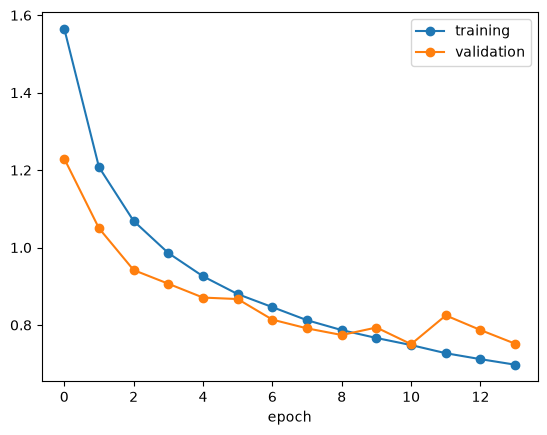

C:\Users\sakar\AppData\Local\Temp\ipykernel_37524\621246671.py:13: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  df_times_dropout.loc[len(df_times_dropout)] = ["Keski suoritusaika", sum(timer_dropout.epoch_times) / len(timer_dropout.epoch_times)]


Epoch,Aika (s)
1,34.46
2,33.39
3,33.53
4,33.49
5,33.03
6,34.97
7,33.10
8,33.81
9,33.60
10,33.45


In [16]:
test_loss_dropout, test_accuracy_dropout = model_dropout.evaluate(x_test, y_test, verbose=0)

print(f"Testin menetys (loss): {test_loss_dropout:.4f}")
print(f"Testin tarkkuus (accuracy): {test_accuracy_dropout:.2%}")

plt.plot(history_dropout.history["loss"], marker="o", label="training")
plt.plot(history_dropout.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

df_times_dropout = pd.DataFrame({"Epoch": range(1, len(timer_dropout.epoch_times) + 1), "Aika (s)": timer_dropout.epoch_times})
df_times_dropout.loc[len(df_times_dropout)] = ["Keski suoritusaika", sum(timer_dropout.epoch_times) / len(timer_dropout.epoch_times)]
df_times_dropout.loc[len(df_times_dropout)] = ["Kokonaissuoritusaika", sum(timer_dropout.epoch_times)]

display(df_times_dropout.style.hide(axis="index").format({"Aika (s)": "{:.2f}"}))

## 5.2 Data augmentation
Kokeillaan datan monipuolistamista kääntämällä kuvia vaakasuunnassa (RandomFlip) ja siirtämällä niitä hieman (RandomTranslation). Tämä pakottaa mallin oppimaan yleispätevämpiä piirteitä sen sijaan, että se opettelisi harjoituskuvat ulkoa.

In [8]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
])

model_aug = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    data_augmentation,
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

model_aug.compile(
    optimizer="adam", 
    loss="sparse_categorical_crossentropy", 
    metrics=["accuracy"]
)

timer_aug = EpochTimer()

history_aug = model_aug.fit(
    x_train, y_train, 
    epochs=20, 
    validation_split=0.1, 
    callbacks=[stop, timer_aug], 
    verbose=2
)

history_aug.history["epoch_time_seconds"] = timer_aug.epoch_times

Epoch 1/20
1407/1407 - 55s - 39ms/step - accuracy: 0.4159 - loss: 1.6141 - val_accuracy: 0.5588 - val_loss: 1.2596
Epoch 2/20
1407/1407 - 44s - 31ms/step - accuracy: 0.5439 - loss: 1.2868 - val_accuracy: 0.6206 - val_loss: 1.0821
Epoch 3/20
1407/1407 - 45s - 32ms/step - accuracy: 0.5941 - loss: 1.1462 - val_accuracy: 0.6618 - val_loss: 0.9839
Epoch 4/20
1407/1407 - 43s - 31ms/step - accuracy: 0.6276 - loss: 1.0643 - val_accuracy: 0.6756 - val_loss: 0.9375
Epoch 5/20
1407/1407 - 40s - 29ms/step - accuracy: 0.6485 - loss: 1.0088 - val_accuracy: 0.6872 - val_loss: 0.9063
Epoch 6/20
1407/1407 - 40s - 29ms/step - accuracy: 0.6641 - loss: 0.9658 - val_accuracy: 0.7104 - val_loss: 0.8603
Epoch 7/20
1407/1407 - 40s - 29ms/step - accuracy: 0.6767 - loss: 0.9316 - val_accuracy: 0.7054 - val_loss: 0.8456
Epoch 8/20
1407/1407 - 41s - 29ms/step - accuracy: 0.6889 - loss: 0.8968 - val_accuracy: 0.7058 - val_loss: 0.8369
Epoch 9/20
1407/1407 - 45s - 32ms/step - accuracy: 0.6968 - loss: 0.8732 - val_a

Testin menetys (loss): 0.7901
Testin tarkkuus (accuracy): 73.68%


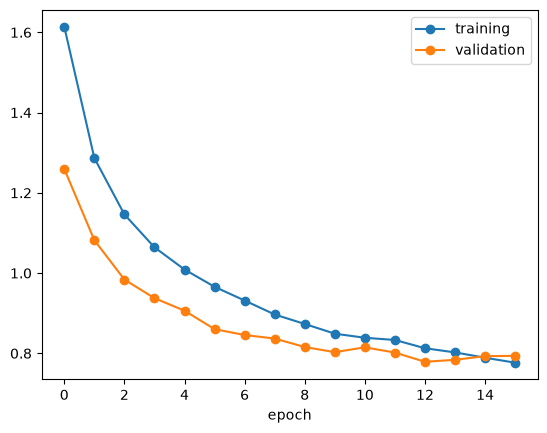

C:\Users\sakar\AppData\Local\Temp\ipykernel_37524\896252558.py:13: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  df_times_aug.loc[len(df_times_aug)] = ["Keski suoritusaika", sum(timer_aug.epoch_times) / len(timer_aug.epoch_times)]


Epoch,Aika (s)
1,55.42
2,44.11
3,44.88
4,43.41
5,40.26
6,40.17
7,40.44
8,41.48
9,44.85
10,43.58


In [9]:
test_loss_aug, test_accuracy_aug = model_aug.evaluate(x_test, y_test, verbose=0)

print(f"Testin menetys (loss): {test_loss_aug:.4f}")
print(f"Testin tarkkuus (accuracy): {test_accuracy_aug:.2%}")

plt.plot(history_aug.history["loss"], marker="o", label="training")
plt.plot(history_aug.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

df_times_aug = pd.DataFrame({"Epoch": range(1, len(timer_aug.epoch_times) + 1), "Aika (s)": timer_aug.epoch_times})
df_times_aug.loc[len(df_times_aug)] = ["Keski suoritusaika", sum(timer_aug.epoch_times) / len(timer_aug.epoch_times)]
df_times_aug.loc[len(df_times_aug)] = ["Kokonaissuoritusaika", sum(timer_aug.epoch_times)]

display(df_times_aug.style.hide(axis="index").format({"Aika (s)": "{:.2f}"}))

## 5.4 Batch Normalization
Lisätään BatchNormalization-kerrokset konvoluutiokerrosten jälkeen. Tämä normalisoi kerrosten väliset syötteet, mikä vakauttaa ja nopeuttaa oppimista. 

In [10]:
model_bn = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

model_bn.compile(
    optimizer="adam", 
    loss="sparse_categorical_crossentropy", 
    metrics=["accuracy"]
)

timer_bn = EpochTimer()

history_bn = model_bn.fit(
    x_train, y_train, 
    epochs=20, 
    validation_split=0.1, 
    callbacks=[stop, timer_bn], 
    verbose=2
)

history_bn.history["epoch_time_seconds"] = timer_bn.epoch_times

Epoch 1/20
1407/1407 - 69s - 49ms/step - accuracy: 0.5103 - loss: 1.4114 - val_accuracy: 0.5522 - val_loss: 1.2723
Epoch 2/20
1407/1407 - 65s - 46ms/step - accuracy: 0.6428 - loss: 1.0237 - val_accuracy: 0.6596 - val_loss: 1.0063
Epoch 3/20
1407/1407 - 64s - 45ms/step - accuracy: 0.6972 - loss: 0.8687 - val_accuracy: 0.6438 - val_loss: 1.0635
Epoch 4/20
1407/1407 - 81s - 57ms/step - accuracy: 0.7320 - loss: 0.7737 - val_accuracy: 0.6782 - val_loss: 0.9593
Epoch 5/20
1407/1407 - 62s - 44ms/step - accuracy: 0.7560 - loss: 0.7038 - val_accuracy: 0.6754 - val_loss: 1.0080
Epoch 6/20
1407/1407 - 63s - 45ms/step - accuracy: 0.7794 - loss: 0.6433 - val_accuracy: 0.6956 - val_loss: 0.9833
Epoch 7/20
1407/1407 - 64s - 46ms/step - accuracy: 0.7946 - loss: 0.5961 - val_accuracy: 0.6726 - val_loss: 1.0814


Testin menetys (loss): 0.9820
Testin tarkkuus (accuracy): 67.26%


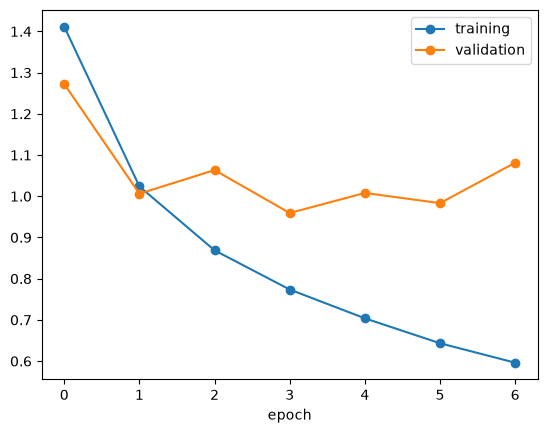

C:\Users\sakar\AppData\Local\Temp\ipykernel_37524\1557979354.py:13: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  df_times_bn.loc[len(df_times_bn)] = ["Keski suoritusaika", sum(timer_bn.epoch_times) / len(timer_bn.epoch_times)]


Epoch,Aika (s)
1,68.67
2,64.51
3,63.99
4,80.78
5,62.42
6,63.29
7,64.15
Keski suoritusaika,66.83
Kokonaissuoritusaika,467.80


In [11]:
test_loss_bn, test_accuracy_bn = model_bn.evaluate(x_test, y_test, verbose=0)

print(f"Testin menetys (loss): {test_loss_bn:.4f}")
print(f"Testin tarkkuus (accuracy): {test_accuracy_bn:.2%}")

plt.plot(history_bn.history["loss"], marker="o", label="training")
plt.plot(history_bn.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

df_times_bn = pd.DataFrame({"Epoch": range(1, len(timer_bn.epoch_times) + 1), "Aika (s)": timer_bn.epoch_times})
df_times_bn.loc[len(df_times_bn)] = ["Keski suoritusaika", sum(timer_bn.epoch_times) / len(timer_bn.epoch_times)]
df_times_bn.loc[len(df_times_bn)] = ["Kokonaissuoritusaika", sum(timer_bn.epoch_times)]

display(df_times_bn.style.hide(axis="index").format({"Aika (s)": "{:.2f}"}))

In [20]:
print("Regularisointien vertailu")
print("")
print(f"Baseline (32/32/64): {test_accuracy_baseline:.2%}")
print(f"Dropout (0.3):       {test_accuracy_dropout:.2%}")
print(f"Augmentaatio:        {test_accuracy_aug:.2%}")
print(f"Batch Normalization: {test_accuracy_bn:.2%}")

Regularisointien vertailu

Baseline (32/32/64): 70.98%
Dropout (0.3):       73.13%
Augmentaatio:        73.68%
Batch Normalization: 67.26%


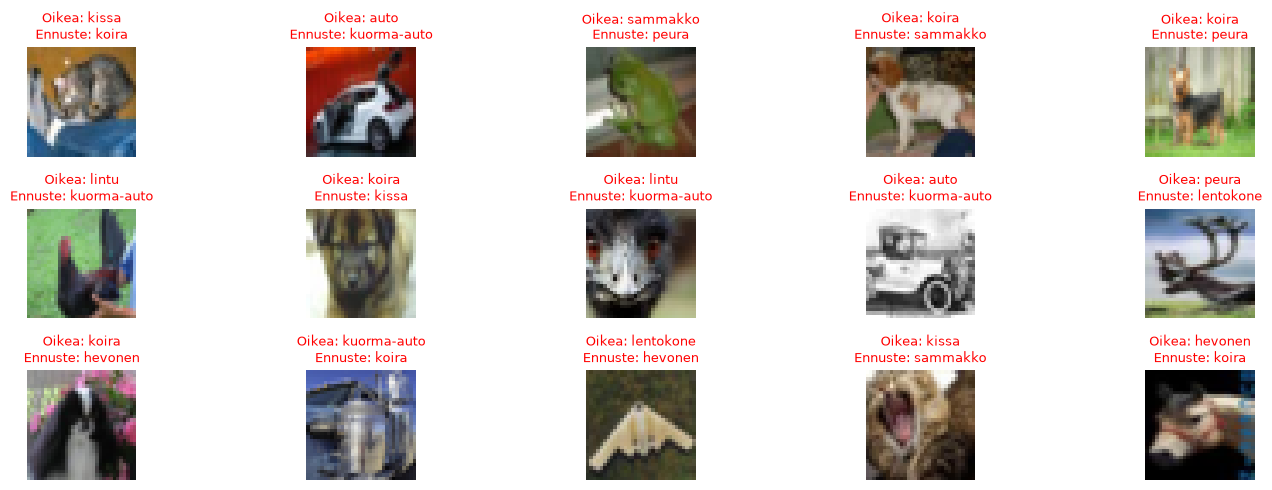

In [21]:
y_pred_aug = model_aug.predict(x_test, verbose=0)
y_pred_classes = np.argmax(y_pred_aug, axis=1)
y_true = y_test.flatten()
wrong_indices = np.where(y_pred_classes != y_true)[0]

plt.figure(figsize=(15, 5))
for i, idx in enumerate(wrong_indices[:15]):
    plt.subplot(3, 5, i+1)
    plt.imshow(x_test[idx])
    plt.title(f"Oikea: {class_names[y_true[idx]]}\nEnnuste: {class_names[y_pred_classes[idx]]}", fontsize=9, color="red")
    plt.axis("off")
plt.tight_layout()
plt.show()